# Tutorial 4: The `FloatingLayout` Object

A `FloatingLayout` object is a subclass of the `Layout` object. This means that it has access to all of the normal functionality of a `Layout` but also builds upon it with
extra funcionalities in order to design and constrain mooring system geometries.

In this tutorial we will see how to utilise these added functionalities to design mooring layouts, and understand the conventions used in LayOWt.

In [73]:
import matplotlib.pyplot as plt
from layowt.layouts import FloatingLayout
from layowt.grids import Grid

## 1. Floating Platform Coordinate System Convention

LayOWt uses a local reference system for the floating platforms in order to define the platform and mooring design before transforming the features into the global coordinate reference
system.

### 1.1 X-Y Plane
The platform local reference frame is defined as an x-y plane (y-vertical, x-horizontal) with the centroid at the turbine location. The image below shows A typical 3-column
semi submersible floating platform design. The turbine is located on column 1 (C1), and serves as the origin of the local reference frame.

### 1.2 Fairleads
By convention, the fairleads (the locations where the mooring lines connect to the platform) are indexed anti-cockwise. In the design shown below line 1 is attached to C1, line 2 to C2, and line 3 to C3.

![platform_rf](img/floating_platform_local_reference.png)

Let's see an example of how we could use LayOWt to replicate the example platform.
Let's create a `FloatingLayout` from a single point and generate some mooring lines to see what we end up with.


(<Figure size 576x432 with 1 Axes>, <AxesSubplot:>)

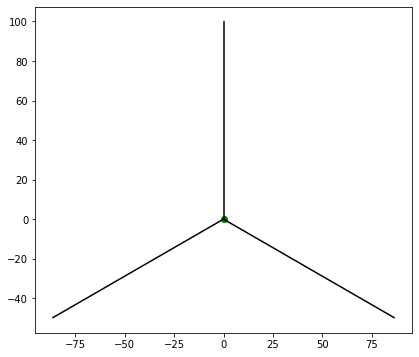

In [74]:
layout = FloatingLayout(Grid(n_rows=1, n_cols=1))
# Generate a mooring system with 3 mooring lines per platform of length 100.
layout.generate_moorings(n_moorings=3, radius=100)
layout.plot()

We have created something that looks similar to the example but not quite right. We have the correct number of mooring lines and the bearing at which they leave the platform s correct
(even spacing of 120°) starting at 0° with line 1. However, all mooring lines have their fairleads at the same location (turbine position) and this is not quite right.

We can define the fairlead locations for all mooring lines in the platform local reference frame using the `mooring_offsets` argument to the `generate_moorings` method.
This argument takes in a list of coordinate-tuples for each of the mooring fairleads. In this example we will pass a list of 3 tuple pairs.

Let's assume that the vertical distance between C1 ancd C2/C3 is 20 metres, and the horizontal distance between C1 and C2 & C3 is 15 metres.

(<Figure size 576x432 with 1 Axes>, <AxesSubplot:>)

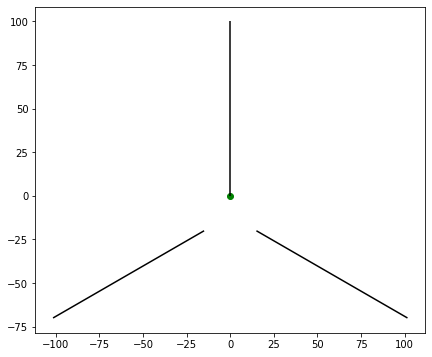

In [75]:
layout.generate_moorings(n_moorings=3, radius=100, mooring_offsets=[(0, 0), (-15, -20), (15, -20)])
layout.plot()

Now we have something more like the example!

### 1.3 Platform Bearing
Depending on the wind and wave roses for the project, we sometimes have to reorient the platform design to optimise the mooring system for environmental loads.
The convention used by LayOWt is that platform bearings use a clockwise convention starting at True North as 0°.

Let's take the same example as above and rotate the full system by 30°.

(<Figure size 576x432 with 1 Axes>, <AxesSubplot:>)

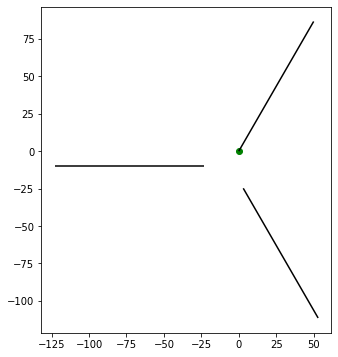

In [76]:
layout.generate_moorings(n_moorings=3, radius=100, mooring_offsets=[(0, 0), (-15, -20), (15, -20)], platform_bearing=30)
layout.plot()

### 1.4 Mooring Bearings
Just like with the platform, the bearings at which the mooring lines leave the platform (prior to the platform bearing rotation) can be specified by the user.
This can be done with the `mooring_bearings` argument.
Lets make an example where lines 2 and 3 have bearings of 270° and 90° respectively.

(-100.0, 100.0)

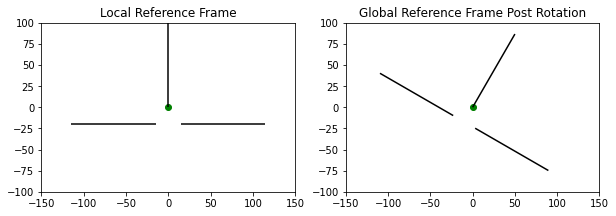

In [77]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10))

layout.generate_moorings(n_moorings=3, radius=100, mooring_offsets=[(0, 0), (-15, -20), (15, -20)], mooring_bearings=[0, 270, 90])
layout.plot(ax=axs[0])
axs[0].set_title("Local Reference Frame")
axs[0].set_xlim((-150, 150))
axs[0].set_ylim((-100, 100))

layout.generate_moorings(n_moorings=3, radius=100, mooring_offsets=[(0, 0), (-15, -20), (15, -20)], mooring_bearings=[0, 270, 90], platform_bearing=30)
layout.plot(ax=axs[1])
axs[1].set_title("Global Reference Frame Post Rotation")
axs[1].set_xlim((-150, 150))
axs[1].set_ylim((-100, 100))

## 2. Layout Creation
Now that we have covered the basic conventions we can create a full turbine layout and its moorings.

We can follow the initial steps just as we did for a normal `Layout` and then call the `generate_moorings` method. 

(<Figure size 1080x720 with 1 Axes>, <AxesSubplot:>)

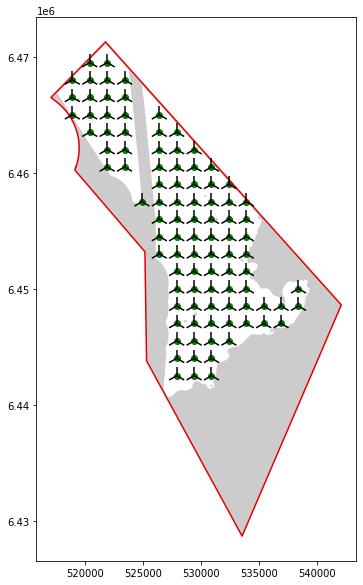

In [78]:
from layowt.layouts import geoms_from_shapefile

areas = geoms_from_shapefile("tutorial_inputs/area.shp")
exclusions = geoms_from_shapefile("tutorial_inputs/exclusions.shp")

grid = Grid(n_rows=30, n_cols=30, scale=250, origin=(areas[0].centroid.x, areas[0].centroid.y))
layout = FloatingLayout(grid, areas=areas, exclusions=exclusions, epsg=32630)

layout.generate_moorings(n_moorings=3, radius=750)

layout.plot(figsize=(15, 10))

We now have a full floating layout with its moorings!

However, opon closer inspection we can see that some of the mooring lines leave the lease area or enter into exclusion zones. In some project this not an acceptable layout design.
We can tackle these issues by applying constraints to the moorings just as we did for the turbines.

### 2.1 Mooring Constraints
We can apply two types of constraints to moorings: area and exclulusions. The area constraint enforces that the entire mooring geometry be contained within specified polygons.The exclusion
constraint enforces that mooring geometries be disjointed (no part must touch or overlap) with any exclusion polygons.

These constraints can be applied using the dedicated `clip_moorings_to_area` and `avoid_mooring_exclusions` methods. They can also be applied directly with the `generate_moorings` method
by passing additional optional arguments.

Let's see how to carry this out using the `generate_moorings` method.

(<Figure size 1080x720 with 1 Axes>, <AxesSubplot:>)

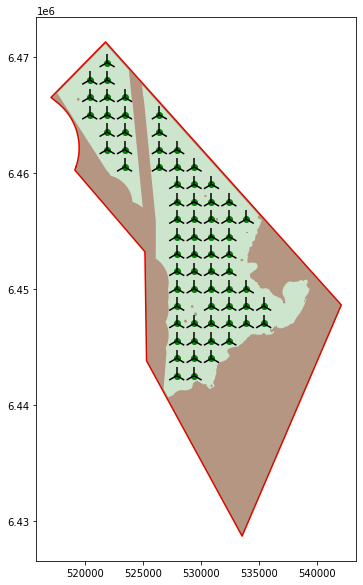

In [79]:
layout.generate_moorings(n_moorings=3, radius=750, contain=True, avoid_exclusions=True)
layout.plot(figsize=(15, 10))

We now have a floating layout compliant with some of the most common design requirements. By passing the `contain` and `avoid_exclusions` arguments as `True`, the `FloatingLayout` has
applied the area and exclusion constraints to the data that was loaded initially to the layout for the turbine positions.

But what if the same constraints do not apply to mooring lines and we wish to apply an independent set of geometric constraints? This can also be accomplished by passing specific geometries
to these constraints.

Lets load a new exclusion geometry that only applies to moorings.

(<Figure size 1080x720 with 1 Axes>, <AxesSubplot:>)

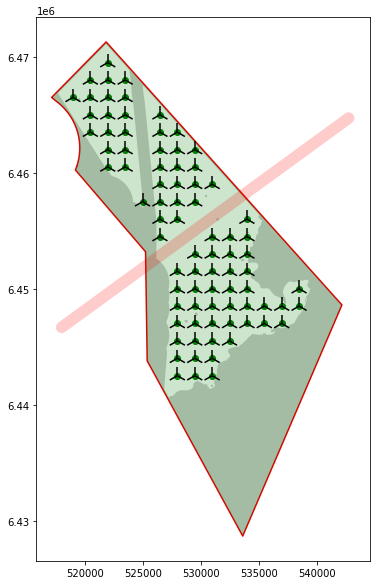

In [80]:
mooring_exclusions = geoms_from_shapefile("tutorial_inputs/mooring_exclusion.shp")

layout.generate_moorings(n_moorings=3, radius=750, contain=True, avoid_exclusions=True, mooring_exclusions=mooring_exclusions)
layout.plot(figsize=(15, 10))

Lets do the same with the area constraint. Lets image that all mooring lines must be constrainted to an internal buffer of 1km from the lease area boundary and apply this constraint
only to the mooring lines.

(<Figure size 1080x720 with 1 Axes>, <AxesSubplot:>)

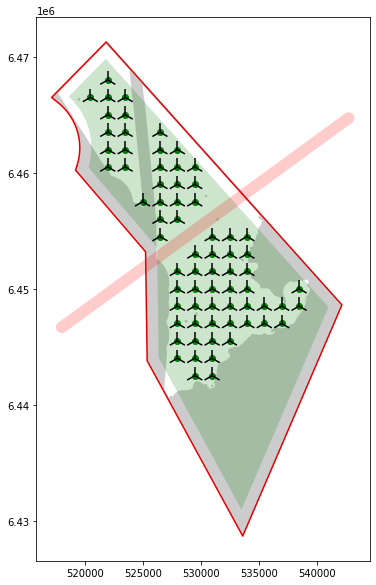

In [81]:
mooring_area = areas[0].buffer(-1000)
layout.generate_moorings(n_moorings=3, radius=750, contain=True, mooring_areas=mooring_area, avoid_exclusions=True, mooring_exclusions=mooring_exclusions)
layout.plot(figsize=(15, 10))

## 3. Mooring Radius
We have seen how to apply spatial constraints to moorings, but we have done so for mooring lines which are of a constant radius throughout the full layout. This is simple enough for
very basic designs, but most detailed designs will have mooring lines of varying lengths depending on the local bathymetry at each turbine location.

We can get around this by passing custom functions or callable objects as the `radius` argument instead of constant values. The only requirements are that the passed callable object
takes a single argument of bathymetry in order to calculate the mooring radius, and that the layout has a loaded bathymetry dataset.

Lets look at a few simple examples:

### 3.1 Using Lambda Functions
We can declare simple lambda functions within the `generate_moorings` method call.

(<Figure size 1080x720 with 1 Axes>, <AxesSubplot:>)

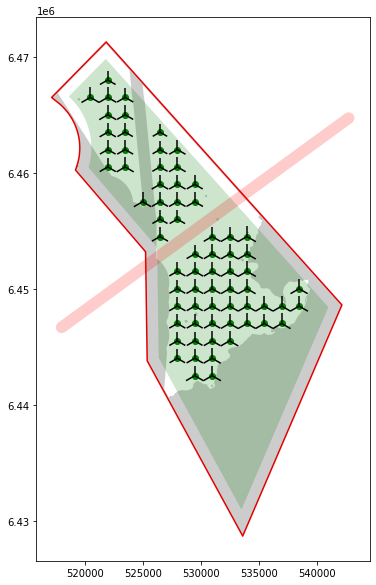

In [82]:
layout.load_bathymetry("tutorial_inputs/bathymetry.tif", limits=(0, 999))

# Simple function that returns a mooring radius 15 times the local bathymetry value.
layout.generate_moorings(n_moorings=3, radius=lambda x: 15*x, contain=True, mooring_areas=mooring_area, avoid_exclusions=True, mooring_exclusions=mooring_exclusions)
layout.plot(figsize=(15, 10))

### 3.2 Using Custom Functions
We can also declare custom functions within our code and pass those as the `radius` argument.

Lets create a function that returns a constant value of 1000m for water depths shallower than 55m or the cube of the water depth for deeper areas

(<Figure size 1080x720 with 1 Axes>, <AxesSubplot:>)

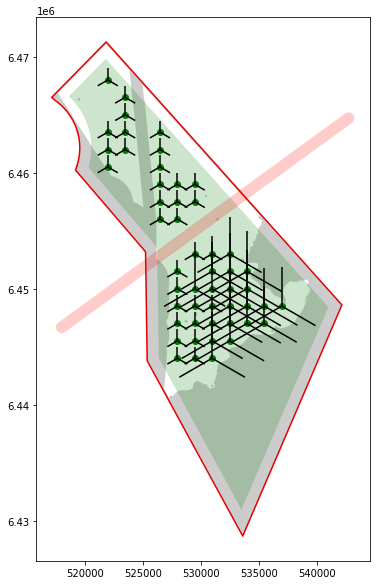

In [83]:
def my_radius_func(x):
    if x < 55:
        return 1000
    
    return x**2

layout.generate_moorings(n_moorings=3, radius=my_radius_func, contain=True, mooring_areas=mooring_area, avoid_exclusions=True, mooring_exclusions=mooring_exclusions)
layout.plot(figsize=(15, 10))

.. tip:: You can check if mooring lines cross each other using the  `mooring_crosses` class property

In [84]:
layout.mooring_crossings

True

### 3.3 Interpolating Data Points
We might also receive mooring length vs bathymetry data points from simulations and wish to interpolate between them.
We can also pass interpolators to calculate mooring radius.

Let's create an example curve and see what it looks like.

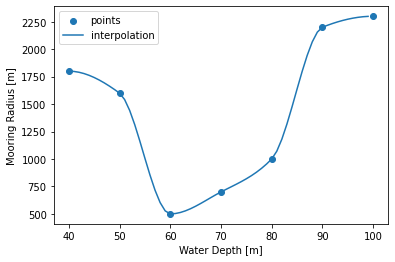

In [85]:
import numpy as np
from scipy.interpolate import PchipInterpolator

water_depth = np.arange(40, 110, 10)
mooring_radius = [1800, 1600, 500, 700, 1000, 2200, 2300]

interpolator = PchipInterpolator(water_depth, mooring_radius)

fig, ax = plt.subplots()
ax.scatter(water_depth, mooring_radius, label="points")
ax.plot(np.arange(40, 100), interpolator(np.arange(40, 100)), label="interpolation")
ax.set_xlabel("Water Depth [m]")
ax.set_ylabel("Mooring Radius [m]")
ax.legend()

Lets apply this curve without any mooring constraints to see the impact on the full area.

(<Figure size 1080x720 with 2 Axes>, <AxesSubplot:>)

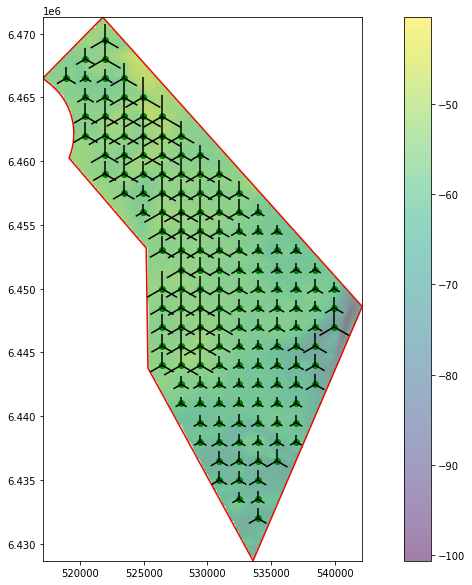

In [86]:
layout = FloatingLayout(grid, areas=areas, epsg=32630)
layout.load_bathymetry("tutorial_inputs/bathymetry.tif", limits=(0, 999))
layout.generate_moorings(n_moorings=3, radius=interpolator, contain=True)
layout.plot(figsize=(15, 10), show_bathy=True)

## 4. A More Complex Example
Lets finish this tutorial by trying to build a more complex example, using some unusual mooring designs.

Lets build a layout with the following characteristics:
- Minimum water depth of 60m;
- Assume a 3-column semi-submersible platform design;
- 6 moorings per platform, with 2 moorings at each of the 3 columns;
- Platform bearing of 225°; and
- Custom Mooring Radius Function

(<Figure size 720x720 with 2 Axes>, <AxesSubplot:>)

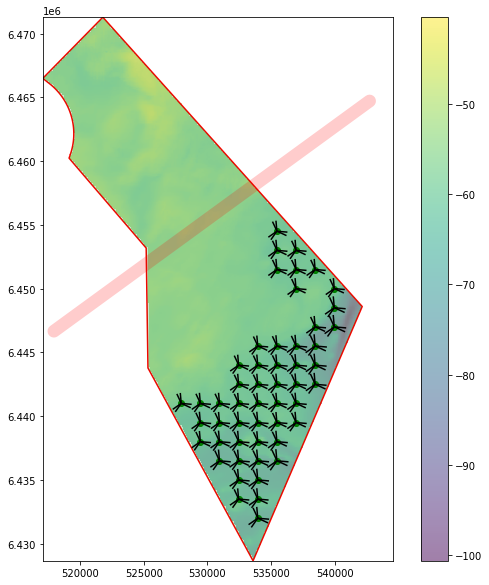

In [95]:
def radius_func(x):
    return 500 + 5*x

mooring_offsets = [(0, 0), (0, 0), (-15, -20), (-15, -20), (15, -20), (15, -20)]
mooring_bearings = [10, 350, 250, 230, 130, 110]

grid = Grid(n_rows=30, n_cols=30, scale=250, origin=(areas[0].centroid.x, areas[0].centroid.y))
layout = FloatingLayout(grid, areas=areas, epsg=32630)
layout.load_bathymetry("tutorial_inputs/bathymetry.tif", limits=(60, 999))
layout.generate_moorings(n_moorings=6, radius=radius_func, platform_bearing=225, mooring_bearings=mooring_bearings,
                         mooring_offsets=mooring_offsets, contain=True, avoid_exclusions=True, mooring_exclusions=mooring_exclusions)
layout.plot(figsize=(10,10), show_bathy=True)